In [1]:
# Step 1: Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

In [2]:
# Step 2: Load the dataset from the notebook directory
df = pd.read_csv("emails.csv")

print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (5172, 3002)
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]


In [3]:
# Step 3: Remove missing values, duplicates and email identifier
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

X = df.drop(columns=["Email No.", "Prediction"], errors="ignore")
y = df["Prediction"]

print("Features shape:", X.shape)
print("Target distribution:\n", y.value_counts())

Features shape: (5172, 3000)
Target distribution:
 Prediction
0    3672
1    1500
Name: count, dtype: int64


In [4]:
# Step 4: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 4137
Testing samples: 1035


In [5]:
# Step 5: Train and evaluate KNN
knn = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=7)
)

knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

print("KNN Classification Report")
print(classification_report(y_test, knn_pred, zero_division=0))

KNN Classification Report
              precision    recall  f1-score   support

           0       0.97      0.74      0.84       735
           1       0.60      0.95      0.73       300

    accuracy                           0.80      1035
   macro avg       0.79      0.84      0.79      1035
weighted avg       0.86      0.80      0.81      1035



In [11]:
# Step 6: Train and evaluate SVM
from sklearn.svm import SVC

svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="linear", C=1.0)
)

svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)

print("SVM Classification Report")
print(classification_report(y_test, svm_pred, zero_division=0))

SVM Classification Report
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       735
           1       0.91      0.92      0.92       300

    accuracy                           0.95      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



In [7]:
# Step 7: Calculate evaluation metrics
results = pd.DataFrame({
    "Model": ["KNN", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred)
    ],
    "Precision": [
        precision_score(y_test, knn_pred, zero_division=0),
        precision_score(y_test, svm_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, knn_pred, zero_division=0),
        recall_score(y_test, svm_pred, zero_division=0)
    ],
    "F1-Score": [
        f1_score(y_test, knn_pred, zero_division=0),
        f1_score(y_test, svm_pred, zero_division=0)
    ]
})

print(results.round(4))

  Model  Accuracy  Precision  Recall  F1-Score
0   KNN    0.8010     0.5992  0.9467    0.7339
1   SVM    0.9343     0.8372  0.9600    0.8944


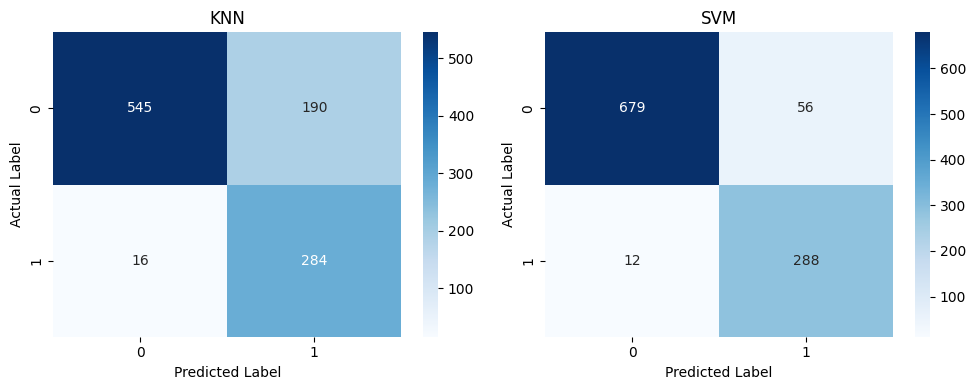

In [8]:
# Step 8: Visualize actual and predicted classifications
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, pred, name in zip(
    axes, [knn_pred, svm_pred], ["KNN", "SVM"]
):
    sns.heatmap(
        confusion_matrix(y_test, pred),
        annot=True, fmt="d", cmap="Blues", ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

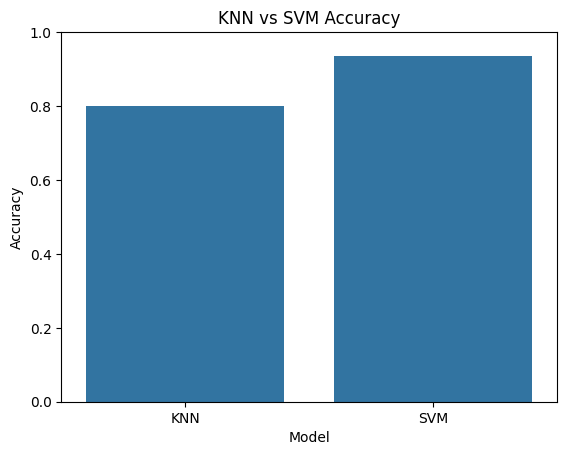

In [9]:
# Step 9: Plot the accuracy of both models
sns.barplot(data=results, x="Model", y="Accuracy")
plt.title("KNN vs SVM Accuracy")
plt.ylim(0, 1)
plt.show()

In [10]:
# Step 10: Display the best model based on F1-score
best_model = results.loc[results["F1-Score"].idxmax(), "Model"]

print("Best model based on F1-score:", best_model)
print("Model comparison:\n", results.round(4))

Best model based on F1-score: SVM
Model comparison:
   Model  Accuracy  Precision  Recall  F1-Score
0   KNN    0.8010     0.5992  0.9467    0.7339
1   SVM    0.9343     0.8372  0.9600    0.8944
